In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

In [3]:
def load_dataset(file_path, target_column):
  df = pd.read_csv(file_path)
  df = df.drop(columns=["customerID"])
  # TotalCharges is stored as text; blanks become NaN
  df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
  X = df.drop(columns=[target_column])
  y = (df[target_column] == "Yes").astype(int)
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42, stratify=y
  )
  return df, X_train, X_test, y_train, y_test

In [4]:
def preprocess_data(X_train, X_test):
  train_df = X_train.copy()
  test_df = X_test.copy()

  numerical_cols = train_df.select_dtypes(include=[np.number]).columns
  categorical_cols = train_df.select_dtypes(exclude=[np.number]).columns

  # Fill missing values using the training data only
  for col in numerical_cols:
    median = train_df[col].median()
    train_df[col] = train_df[col].fillna(median)
    test_df[col] = test_df[col].fillna(median)

  for col in categorical_cols:
    mode = train_df[col].mode()[0]
    train_df[col] = train_df[col].fillna(mode)
    test_df[col] = test_df[col].fillna(mode)

  # One-hot encode the categorical columns
  encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
  train_encoded = pd.DataFrame(
      encoder.fit_transform(train_df[categorical_cols]),
      columns=encoder.get_feature_names_out(categorical_cols),
      index=train_df.index,
  )
  test_encoded = pd.DataFrame(
      encoder.transform(test_df[categorical_cols]),
      columns=encoder.get_feature_names_out(categorical_cols),
      index=test_df.index,
  )
  train_df = pd.concat([train_df[numerical_cols], train_encoded], axis=1)
  test_df = pd.concat([test_df[numerical_cols], test_encoded], axis=1)

  return train_df, test_df

In [5]:
def plot_class_distribution(y_train, y_resampled):
  fig, axes = plt.subplots(1, 2, figsize=(10, 4))

  sns.countplot(x=y_train, ax=axes[0])
  axes[0].set_title("Training Set: Before SMOTE")
  axes[0].set_xlabel("Churn")

  sns.countplot(x=y_resampled, ax=axes[1])
  axes[1].set_title("Training Set: After SMOTE")
  axes[1].set_xlabel("Churn")

  plt.tight_layout()
  plt.show()

In [6]:
def build_pipeline(model):
  # SMOTE runs inside the pipeline so it only ever sees the training folds
  return Pipeline([("smote", SMOTE(random_state=42)), ("model", model)])

In [7]:
def print_scores(name, y_test, y_pred, y_proba, cv_scores):
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_proba)
  print(f"\n=== {name} ===")
  print(f"CV ROC-AUC (5-fold): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
  print(f"Accuracy: {accuracy:.4f}")
  print(f"Precision: {precision:.4f}")
  print(f"Recall: {recall:.4f}")
  print(f"F1: {f1:.4f}")
  print(f"Test ROC-AUC: {roc_auc:.4f}")
  print("\nClassification report:")
  print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))
  return {
      "Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1": f1,
      "CV ROC-AUC": cv_scores.mean(),
      "Test ROC-AUC": roc_auc,
  }

In [8]:
def train_classifier(name, model, X_train, X_test, y_train, y_test):
  pipeline = build_pipeline(model)
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  cv_scores = cross_val_score(
      pipeline, X_train, y_train, cv=cv, scoring="roc_auc"
  )
  pipeline.fit(X_train, y_train)
  y_pred = pipeline.predict(X_test)
  y_proba = pipeline.predict_proba(X_test)[:, 1]
  scores = print_scores(name, y_test, y_pred, y_proba, cv_scores)
  return y_pred, y_proba, scores, pipeline

In [9]:
def plot_roc_curves(y_test, all_probabilities):
  plt.figure(figsize=(8, 6))

  for name in all_probabilities:
    fpr, tpr, _ = roc_curve(y_test, all_probabilities[name])
    auc = roc_auc_score(y_test, all_probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

  plt.plot([0, 1], [0, 1], color="red", linestyle="--", label="Random")
  plt.xlabel("False Positive Rate")
  plt.ylabel("True Positive Rate")
  plt.title("ROC Curves")
  plt.legend(loc="lower right")
  plt.tight_layout()
  plt.show()

In [10]:
def plot_confusion_matrices(y_test, all_predictions):
  fig, axes = plt.subplots(1, len(all_predictions), figsize=(12, 5))

  for i, name in enumerate(all_predictions):
    cm = confusion_matrix(y_test, all_predictions[name])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=axes[i],
    )
    axes[i].set_title(f"{name}: Confusion Matrix")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

  plt.tight_layout()
  plt.show()

In [11]:
def plot_feature_importances(all_models, feature_names, top_n=10):
  fig, axes = plt.subplots(1, len(all_models), figsize=(16, 6))

  for i, name in enumerate(all_models):
    importances = pd.Series(
        all_models[name].named_steps["model"].feature_importances_,
        index=feature_names,
    )
    top_features = importances.sort_values(ascending=False).head(top_n)
    print(f"\n=== {name}: Top {top_n} Features ===")
    print(top_features.round(4))

    sns.barplot(x=top_features.values, y=top_features.index, ax=axes[i])
    axes[i].set_title(f"{name}: Top {top_n} Feature Importances")
    axes[i].set_xlabel("Importance")

  plt.tight_layout()
  plt.show()

In [12]:
file_path = "CustomerChurn.csv"
target_column = "Churn"

df, X_train, X_test, y_train, y_test = load_dataset(file_path, target_column)
print(df[target_column].value_counts())
print(f"Missing TotalCharges: {df['TotalCharges'].isna().sum()}")

X_train_processed, X_test_processed = preprocess_data(X_train, X_test)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Missing TotalCharges: 11


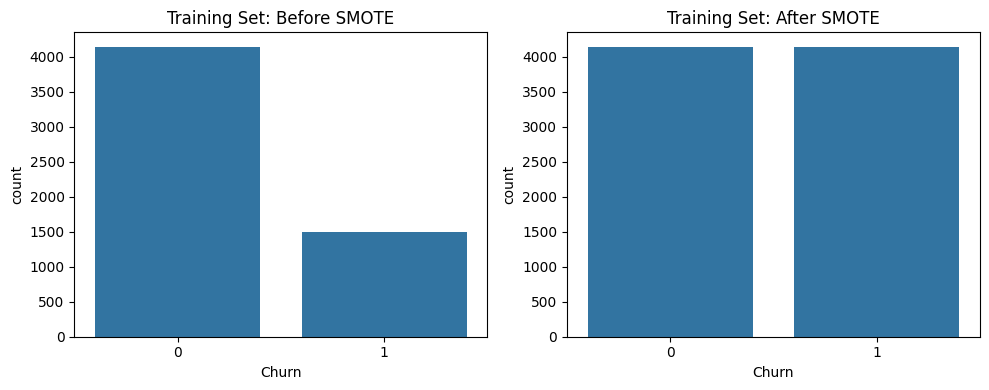

In [13]:
# Show how SMOTE balances the training classes
_, y_resampled = SMOTE(random_state=42).fit_resample(
    X_train_processed, y_train
)
plot_class_distribution(y_train, y_resampled)

In [14]:
rf_pred, rf_proba, rf_scores, rf_model = train_classifier(
    "Random Forest",
    RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    X_train_processed, X_test_processed, y_train, y_test,
)
xgb_pred, xgb_proba, xgb_scores, xgb_model = train_classifier(
    "XGBoost",
    XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        eval_metric="logloss", random_state=42,
    ),
    X_train_processed, X_test_processed, y_train, y_test,
)

print("\n=== Benchmark Summary ===")
print(pd.DataFrame({"Random Forest": rf_scores, "XGBoost": xgb_scores}).T.round(4))


=== Random Forest ===
CV ROC-AUC (5-fold): 0.8398 +/- 0.0094
Accuracy: 0.7779
Precision: 0.5768
Recall: 0.6123
F1: 0.5940
Test ROC-AUC: 0.8356

Classification report:
              precision    recall  f1-score   support

          No       0.86      0.84      0.85      1035
         Yes       0.58      0.61      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409


=== XGBoost ===
CV ROC-AUC (5-fold): 0.8433 +/- 0.0101
Accuracy: 0.7935
Precision: 0.6224
Recall: 0.5642
F1: 0.5919
Test ROC-AUC: 0.8410

Classification report:
              precision    recall  f1-score   support

          No       0.85      0.88      0.86      1035
         Yes       0.62      0.56      0.59       374

    accuracy                           0.79      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.79      0.79      1409


=== Benchmark S

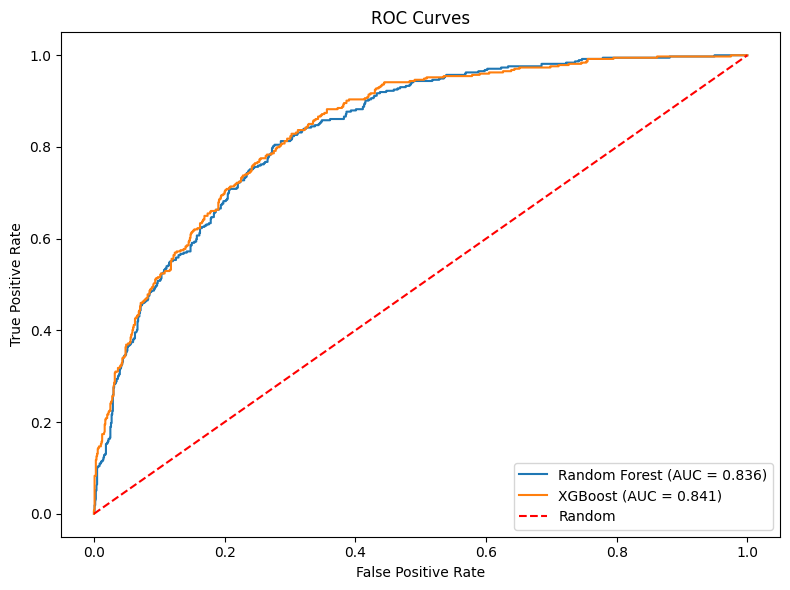

In [15]:
all_probabilities = {"Random Forest": rf_proba, "XGBoost": xgb_proba}
all_predictions = {"Random Forest": rf_pred, "XGBoost": xgb_pred}
all_models = {"Random Forest": rf_model, "XGBoost": xgb_model}

plot_roc_curves(y_test, all_probabilities)

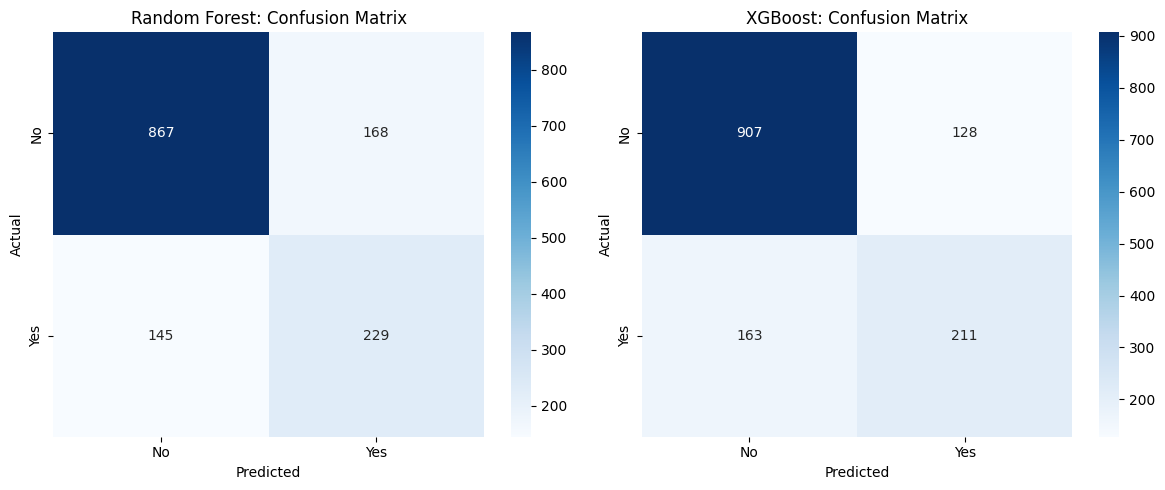

In [16]:
plot_confusion_matrices(y_test, all_predictions)


=== Random Forest: Top 10 Features ===
Contract_Month-to-month           0.1178
OnlineSecurity_No                 0.1013
PaymentMethod_Electronic check    0.0866
TechSupport_No                    0.0765
tenure                            0.0572
TotalCharges                      0.0545
Contract_Two year                 0.0466
OnlineBackup_No                   0.0420
InternetService_Fiber optic       0.0354
PaperlessBilling_Yes              0.0320
dtype: float64

=== XGBoost: Top 10 Features ===
Contract_Month-to-month           0.3116
TechSupport_No                    0.0793
Dependents_Yes                    0.0749
OnlineSecurity_No                 0.0673
InternetService_Fiber optic       0.0529
OnlineBackup_No                   0.0491
PaperlessBilling_Yes              0.0440
PaymentMethod_Electronic check    0.0423
StreamingMovies_Yes               0.0192
StreamingTV_Yes                   0.0178
dtype: float32


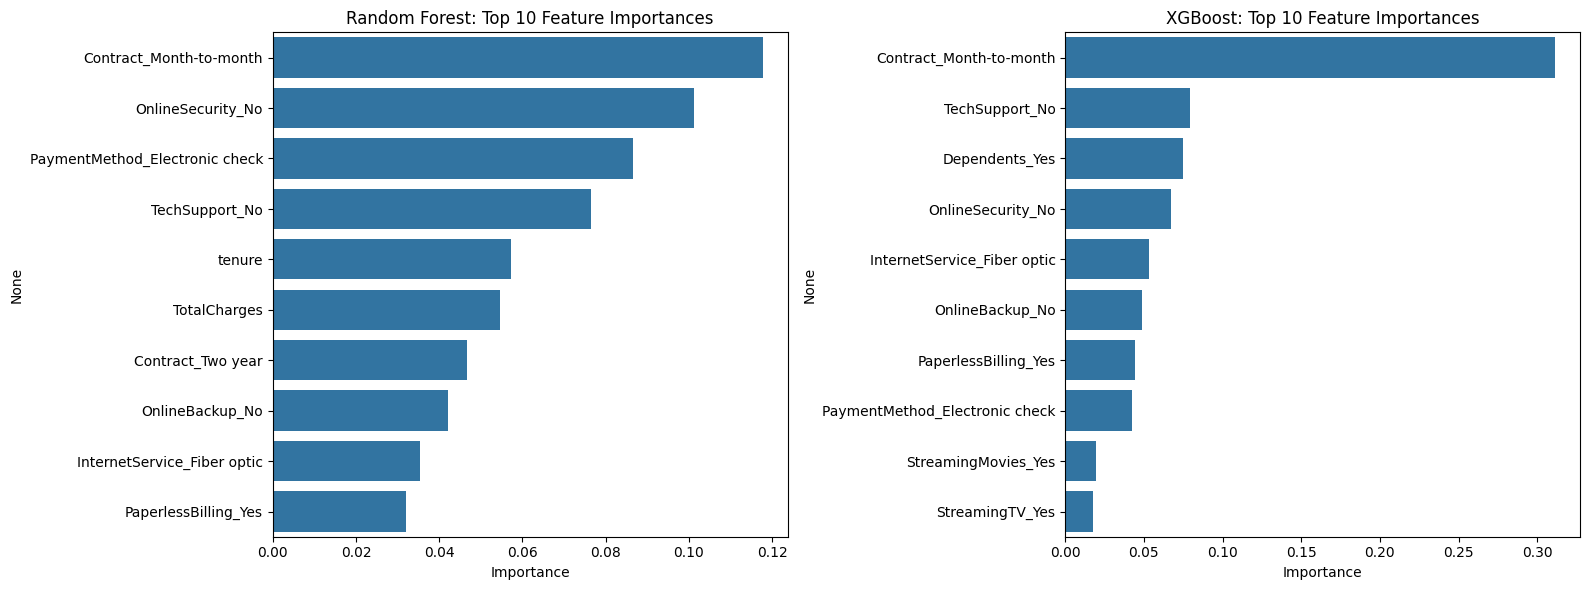

In [17]:
plot_feature_importances(all_models, X_train_processed.columns)